In [1]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt 
from matplotlib.animation import FuncAnimation, PillowWriter
import webbrowser

csv_files = r"C:\Users\rain\Lab8_Data_Visualization_Bacor\spotify_dataset\spotify_top_1000_tracks.csv"
df = pd.read_csv(csv_files)

student_name = "Rain Andrew F. Bacor"
student_id = "TUPM-26-1879"

id_num = int(student_id[-3:])
color_bar = f"#{(id_num * 7) % 256:02x}{(id_num * 3) % 256:02x}{(id_num * 5) % 256:02x}"
color_line = f"#{(id_num * 2) % 256:02x}{(id_num * 9) % 256:02x}{(id_num * 4) % 256:02x}"
grad = ['viridis', 'plasma', 'inferno', 'magma', 'cividis']
chance = (id_num % 3) - 2
cmap_color = grad[chance]

# Data cleaning
# Clean up text columns
# Convert date and export year
df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')
df['year'] = df['release_date'].dt.year
df = df.dropna(subset=['year'])
df['track_name'] = df['track_name'].str.strip()
df['artist'] = df['artist'].str.strip()
df['album'] = df['album'].str.strip()
# Convert 'year' to integer
df['year'] = df['year'].fillna(0).astype(int) 

# Drop unnecessary columns
cols_to_drop = ['spotify_url', 'id', 'release_date']
# Check for and add other common audio feature columns if they exist
if 'time_signature' in df.columns:
 cols_to_drop.append('time_signature')
if 'key' in df.columns:
 cols_to_drop.append('key')
if 'mode' in df.columns:
 cols_to_drop.append('mode')
df = df.drop(columns=cols_to_drop, errors='ignore')


print("Student name:", student_name)
print("Student ID:", student_id)
print("ID Number:", id_num)
print("Color bar:", color_bar)
print("Color line:", color_line)
print("Color map:", cmap_color)



Student name: Rain Andrew F. Bacor
Student ID: TUPM-26-1879
ID Number: 879
Color bar: #094d2b
Color line: #dee7bc
Color map: magma


,track_name,artist,duration_min
710,Lost Boy,Jaden,9.497883
610,I'm Getting Ready,Tasha Cobbs Leonard,8.436667
64,Mirrors,Justin Timberlake,8.069100
63,What Goes Around.../...Comes Around (Interlude),Justin Timberlake,7.476217
622,Achilles Come Down,Gang of Youths,7.035767
689,Never Let Go (Of Me),Baltra,6.909833
682,House Of Balloons / Glass Table Girls,The Weeknd,6.753550
549,Stan,Eminem,6.735100
671,Galvanize,The Chemical Brothers,6.563550
37,After Hours,The Weeknd,6.017100


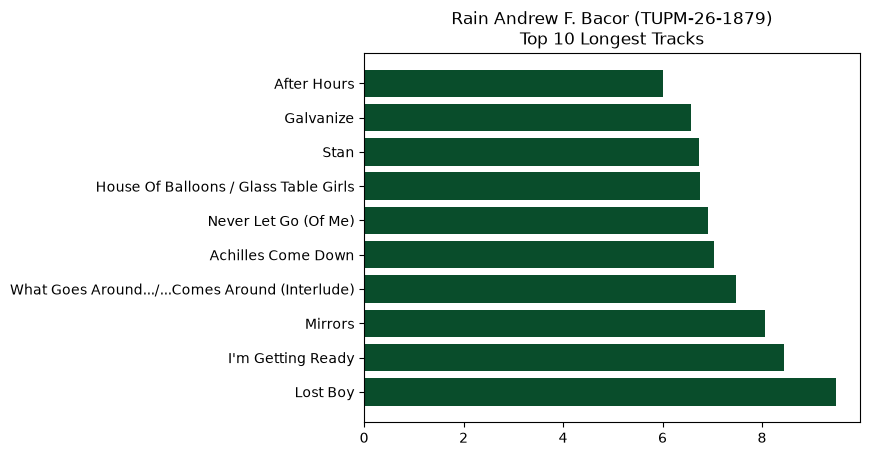

<Figure size 1980x720 with 0 Axes>

In [2]:
# Get the 10 largest values by duration_min using nlargest(). (faster than .sort_values())
top10 = df.nlargest(10, 'duration_min')

# Display the table, only showing track name, artist, and duration.
table_df = top10[['track_name', 'artist', 'duration_min']].copy()

display(table_df)
plt.barh(top10['track_name'], top10['duration_min'], color=color_bar)
plt.title(f"{student_name} ({student_id})\nTop 10 Longest Tracks")
plt.figure(figsize=(19.8, 7.2))
plt.tight_layout()
plt.show()

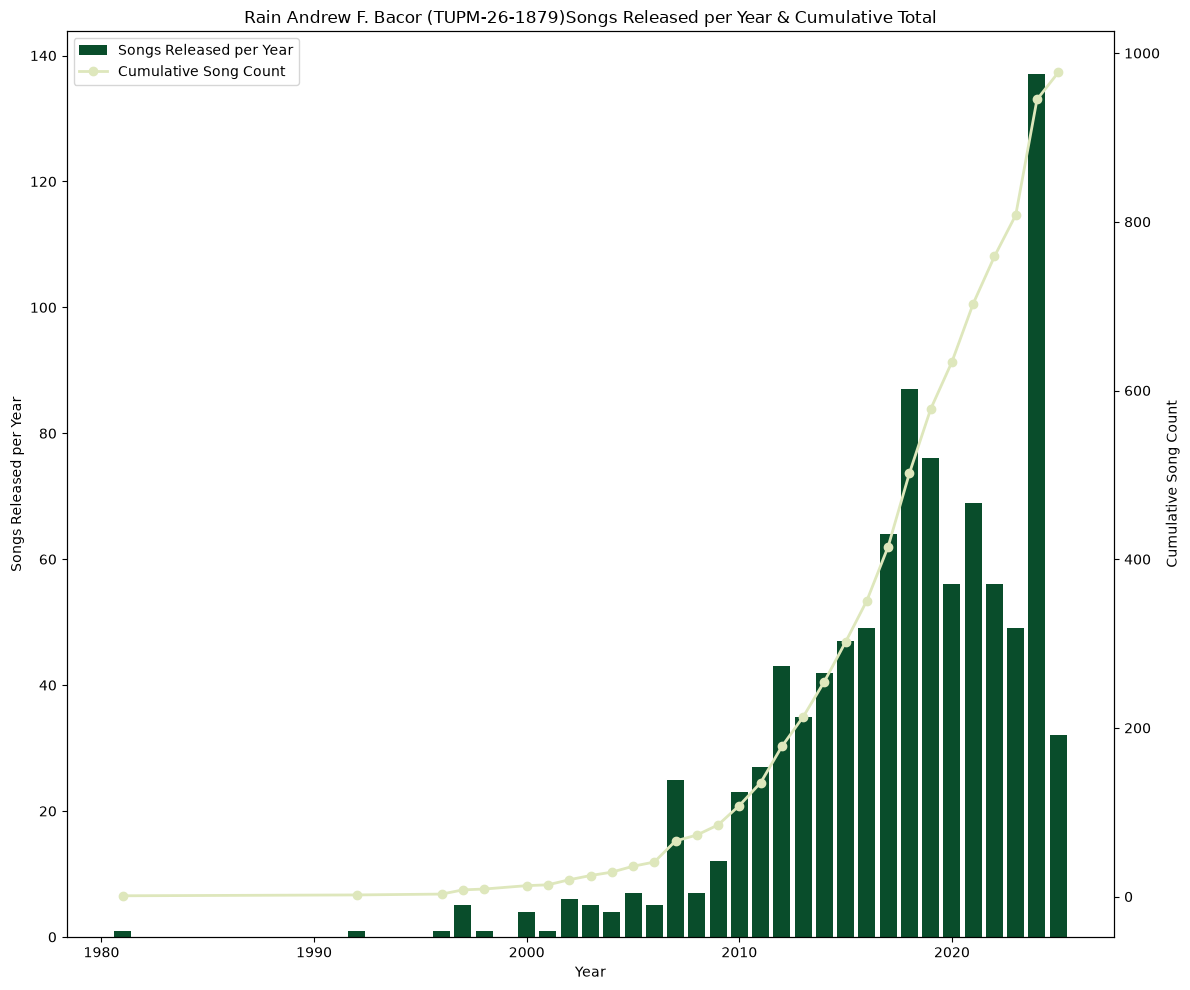

In [3]:
# Initialization of variables to be used later on.
# Group first, then record yearly count and cumulative count.
grouped = df.groupby('year')
yearly_counts = grouped[['track_name']].count().reset_index()
yearly_counts = yearly_counts.sort_values(by='year')
yearly_counts['cumulative_counts'] = yearly_counts['track_name'].cumsum()

fig1, ax1 = plt.subplots(figsize=(12, 10))
ax1.bar(
    yearly_counts['year'],
    yearly_counts['track_name'],
    label='Songs Released per Year',
    color=color_bar,
)

ax1.set_xlabel('Year')
ax1.set_ylabel('Songs Released per Year')

ax2 = ax1.twinx()
ax2.plot(
    yearly_counts['year'],
    yearly_counts['cumulative_counts'],
    color=color_line,
    label='Cumulative Song Count',
    marker='o',
    zorder=5,
    linewidth=2
)
ax2.set_ylabel('Cumulative Song Count')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')
plt.title(f"{student_name} ({student_id})Songs Released per Year & Cumulative Total")
plt.tight_layout()
plt.show()

✅ Hexbin Density Plot Animation has been successfully exported at: c:\Users\rain\Lab8_Data_Visualization_Bacor\Lab8_Data_Visualization_Additional_Exercises\output\yearly_duration_and_popularity_trend.gif


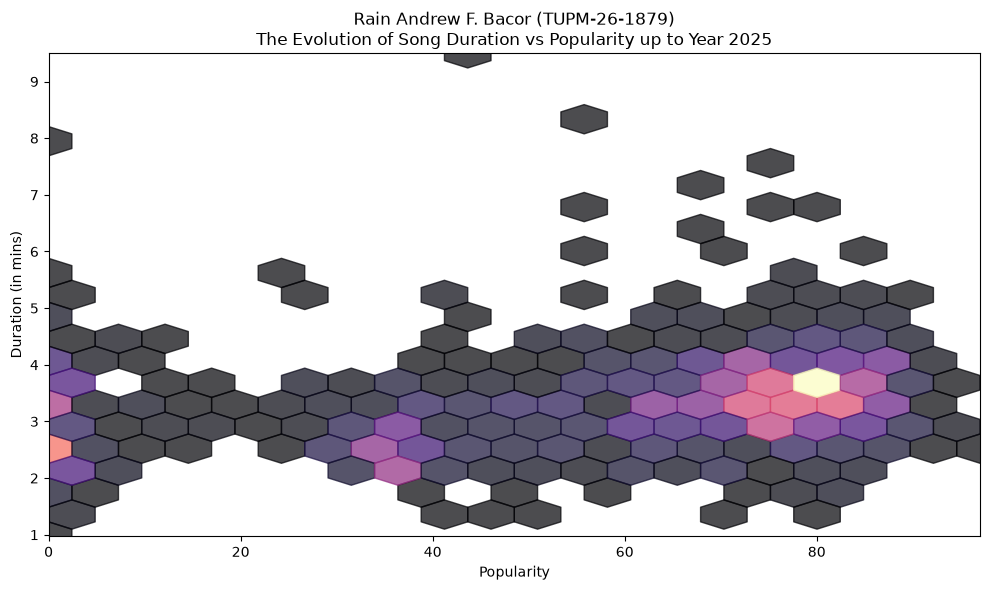

In [4]:
# Subsetting to isolate the needed columns
df = df.dropna(subset=['duration_min', 'popularity', 'year'])
years = sorted(df['year'].unique())

fig, ax = plt.subplots(figsize=(10, 6))

# Setting the range of the plot.
x_min = df['popularity'].min()
x_max = df['popularity'].max()
y_min = df['duration_min'].min()
y_max = df['duration_min'].max()

def update(year):
    # - update(): updates the frame each consequent year with new density and popularity values.
    ax.clear()

    current_year = df[df['year'] <= year]

    hb = plt.hexbin(
        current_year['popularity'],
        current_year['duration_min'],
        cmap=cmap_color,
        gridsize=20,
        mincnt=1, 
        alpha=0.7
    )
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xlabel('Popularity')
    ax.set_ylabel('Duration (in mins)')
    plt.title(f"{student_name} ({student_id})\nThe Evolution of Song Duration vs Popularity up to Year {year}")

    return hb, 
ani = FuncAnimation(fig, update, frames=years, interval=80, repeat=False)

gif_path = Path.cwd() / "output" / "yearly_duration_and_popularity_trend.gif"
ani.save(gif_path, writer=PillowWriter(fps=10))
print("✅ Hexbin Density Plot Animation has been successfully exported at:", gif_path)
plt.tight_layout()
plt.show()

# Opening the browser
webbrowser.open(f"file://{gif_path}")
plt.close(fig)
